# Playground — DeCo-VTON try-on (dataset agnostic)

Virtual try-on with pre-trained [DeCo-VTON](https://huggingface.co/levinna/DeCo-VTON) on an HR-VITON sample. Uses the dataset `agnostic-v3.2` image to derive the mask (person and cloth filenames can differ).

In [1]:
import sys
from pathlib import Path

import torch

sys.path.insert(0, str(Path("../..").resolve()))

from fashion_diffusion.paths import DATA_DIR
from fashion_diffusion.decovton import (
    load_pipeline,
    prepare_inputs,
    run_tryon,
    show_condition_and_mask,
    show_inputs,
    show_result,
)

W1126 10:31:01.248000 68374 .venv/lib/python3.14/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
person_filename = "03195_00.jpg"
cloth_filename = "00009_00.jpg"
split = "train"

person_path = DATA_DIR / split / "image" / person_filename
cloth_path = DATA_DIR / split / "cloth" / cloth_filename
agnostic_path = DATA_DIR / split / "agnostic-v3.2" / person_filename
hf_repo = "levinna/DeCo-VTON"
hf_subfolder = "VITON-HD-512/unet"
device = "mps"
dtype = torch.float16
num_inference_steps = 7

print("==== Input paths:")
print(f"\tperson_path: {person_path}")
print(f"\tcloth_path: {cloth_path}")
print(f"\tagnostic_path: {agnostic_path}")
print(f"\thf_repo: {hf_repo}")
print(f"\thf_subfolder: {hf_subfolder}")
print(f"\tdevice: {device}")
print(f"\tnum_inference_steps: {num_inference_steps}")

==== Input paths:
	person_path: /Users/luigidamico/NoCloudStuff/fashion-diffusion/data/HR-VITON/train/image/03195_00.jpg
	cloth_path: /Users/luigidamico/NoCloudStuff/fashion-diffusion/data/HR-VITON/train/cloth/00009_00.jpg
	agnostic_path: /Users/luigidamico/NoCloudStuff/fashion-diffusion/data/HR-VITON/train/agnostic-v3.2/03195_00.jpg
	hf_repo: levinna/DeCo-VTON
	hf_subfolder: VITON-HD-512/unet
	device: mps
	num_inference_steps: 7


In [3]:
hf_repo

'levinna/DeCo-VTON'

In [4]:
hf_subfolder

'VITON-HD-512/unet'

In [5]:
pipe = load_pipeline(hf_repo, hf_subfolder, device, dtype)

/Users/luigidamico/Documents/GitHub/fashion-diffusion/.venv/lib/python3.14/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


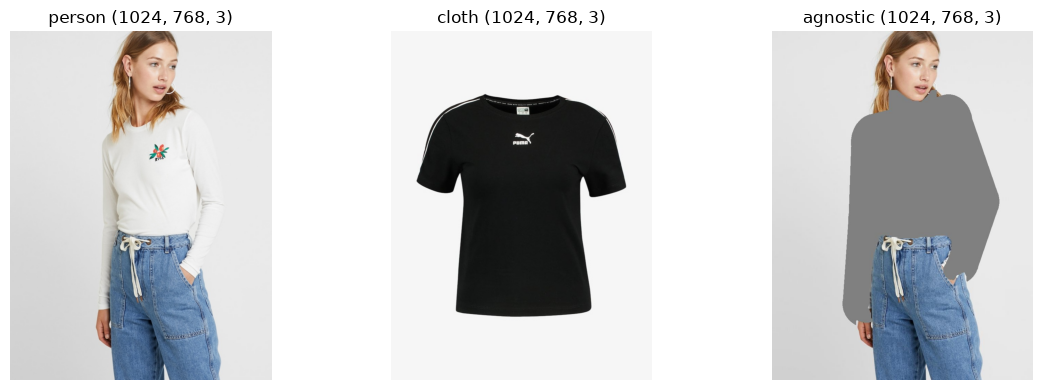

In [6]:
show_inputs(person_path, cloth_path, agnostic_path)

In [7]:
condition, mask = prepare_inputs(person_path, cloth_path, agnostic_path)

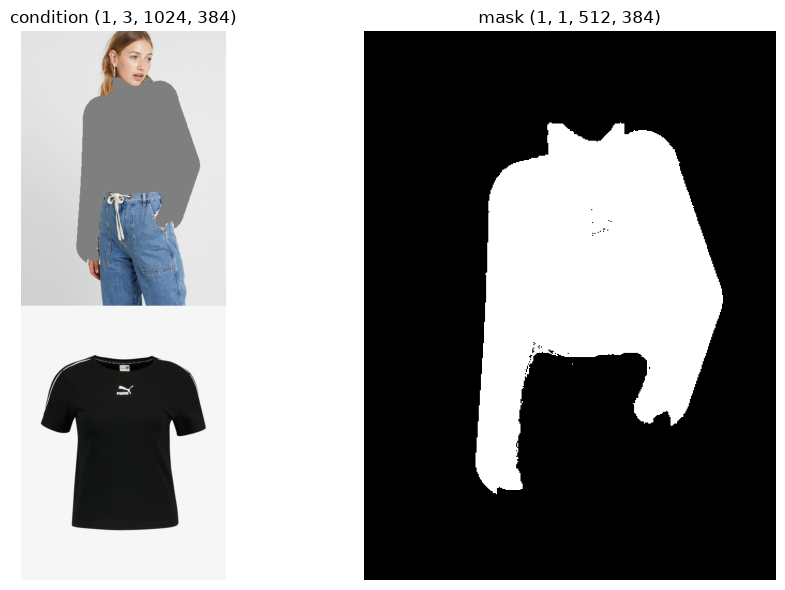

In [8]:
show_condition_and_mask(condition, mask)

In [9]:
result = run_tryon(pipe, condition, mask, num_inference_steps=num_inference_steps)

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/7 [00:00<?, ?it/s]

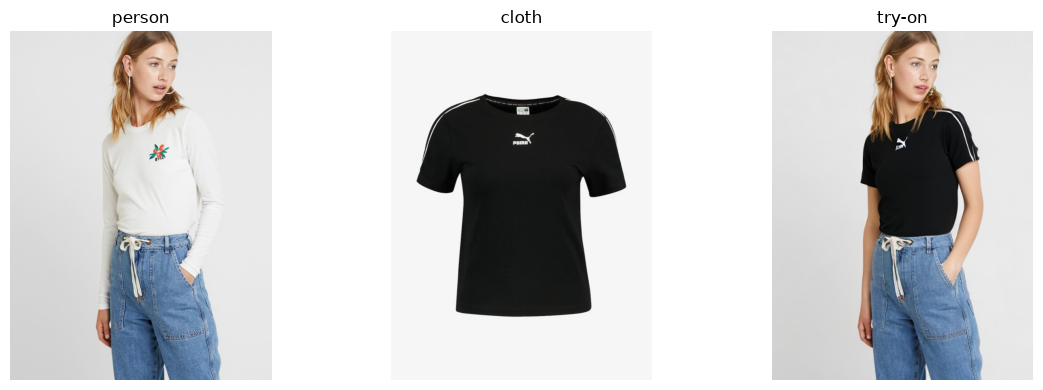

In [10]:
show_result(person_path, cloth_path, result)